In [1]:
from datetime import datetime
from pathlib import Path

import h5py
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
import matplotlib as mpl
import numpy as np

from misc import plots_folder, data_folder
from plotter import ResultLoader

In [2]:
# mpl.rcParams['axes.titlesize'] = 15
# mpl.rcParams['axes.labelsize'] = 18
# mpl.rcParams['xtick.labelsize'] = 15
# mpl.rcParams['ytick.labelsize'] = 15
# mpl.rcParams['legend.fontsize'] = 15
# mpl.rcParams['figure.titlesize'] = 20
# mpl.rcParams['figure.figsize'] = (8, 6)
# mpl.rcParams['text.latex.preamble'] = r'\usepackage{siunitx}' + "\n" + r'\usepackage{physics}'
# # mpl.rcParams["mathtext.fontset"] = "stix"
# # mpl.rcParams["mathtext.default"] = "regular"
#
# prop_cycle = plt.rcParams['axes.prop_cycle']
# colors = prop_cycle.by_key()['color']

In [3]:
mpl.rcdefaults()  # start clean
prd_column_width = 3.39
fig_width = prd_column_width
fig_height = fig_width * 0.75
mpl.rcParams.update({
    # --- Fonts: match REVTeX 4-2 (Times text, newtxmath) ---
    'text.usetex': True,
    'font.family': 'serif',
    'text.latex.preamble': r'''
        \usepackage{amsmath}
        \usepackage{newtxtext}
        \usepackage{newtxmath}
    ''',
    'font.size': 10,          # PRD body text size
    'axes.labelsize': 10,
    'legend.fontsize': 8,     # APS captions/legends are smaller
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.titlesize': 10,

    # --- Figure geometry: fit APS column width 8.6 cm ---
    'figure.figsize': (fig_width, fig_height),   # single column; double: (7.0, 3.0)
    'figure.dpi': 150,               # screen display
    'savefig.dpi': 600,              # raster fallback (prefer vector)
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.01,
    'savefig.format': 'pdf',         # pdflatex/REVTeX workflow
    'pdf.fonttype': 42,              # TrueType: editable, no bitmap glyphs

    # --- Lines & markers: stay legible at small size ---
    'lines.linewidth': 1.2,
    'lines.markersize': 4,
    'axes.linewidth': 0.8,
    'grid.linewidth': 0.5,
    'grid.linestyle': ':',
    'axes.grid': False,              # enable per-figure if needed

    # --- Ticks: APS style (inward on both axes is common in physics figs) ---
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.major.size': 4,
    'ytick.minor.size': 2,
    'xtick.major.pad': 2,
    'ytick.major.pad': 2,

    # --- Legend ---
    'legend.frameon': False,
    'legend.handlelength': 1.5,
    'legend.columnspacing': 1.0,
    'legend.handletextpad': 0.4,

    # --- Misc ---
    'axes.formatter.use_mathtext': True,
    'axes.unicode_minus': False,     # avoids missing minus glyph with usetex
    'figure.autolayout': True,
})

In [4]:
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
gs_color = "black"
es_color = "green"
es_color = "dimgray"
opacity = 0.75
hes_color = (1-opacity)*np.array(mpl.colors.to_rgba("white"))+opacity*np.array(mpl.colors.to_rgba("sienna"))

In [5]:
output_filename = plots_folder
# temp = "2025-09-35"
# output_filename += temp
output_filename += datetime.now().strftime('%Y-%m-%U')  #datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
Path(output_filename).mkdir(parents=True, exist_ok=True)
output_filename += "/"
output_filename

'results/plots/2026-11-45/'

In [6]:
with h5py.File(f"{data_folder}{"2025-09-35"}.hdf5", "r") as f:
    ed_loader = ResultLoader(f["2025-09-03_22-35-17"])
    ed_energy, ed_mass = ed_loader.get_energy_mass({})
    vqe_1_loader = ResultLoader(f["2025-09-02_17-46-07"])  # 4 layers, 5000 max iterations
    vqe_1_energy, vqe_1_mass = vqe_1_loader.get_energy_mass({})
    vqe_1_h_var, vqe_1_mass_h_var = vqe_1_loader.get_hamiltonian_variance_mass({})
    vqe_2_loader = ResultLoader(f["2025-09-03_11-10-56"])  # 4 layers, 20000 max iterations
    vqe_2_energy, vqe_2_mass = vqe_2_loader.get_energy_mass({})
    vqe_2_h_var, vqe_2_mass_h_var = vqe_2_loader.get_hamiltonian_variance_mass({})
    vqe_3_loader = ResultLoader(f["2025-09-03_11-11-36"])  # 2 layers, 20000 max iterations
    vqe_3_energy, vqe_3_mass = vqe_3_loader.get_energy_mass({})
    vqe_3_h_var, vqe_3_mass_h_var = vqe_3_loader.get_hamiltonian_variance_mass({})
    vqe_4_loader = ResultLoader(f["2025-09-03_11-12-33"])  # 8 layers, 20000 max iterations
    vqe_4_energy, vqe_4_mass = vqe_4_loader.get_energy_mass({})
    vqe_4_h_var, vqe_4_mass_h_var = vqe_4_loader.get_hamiltonian_variance_mass({})

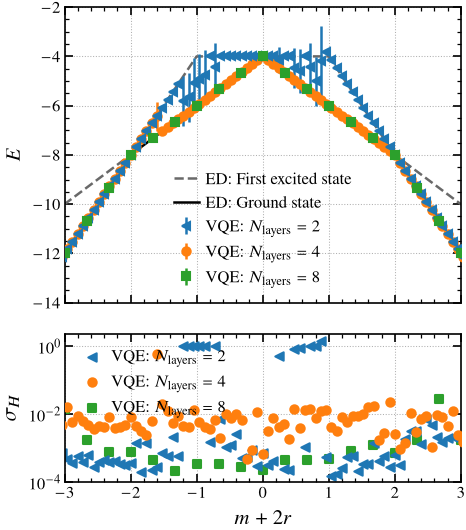

In [22]:
fig, (ax, var_ax) = plt.subplots(2, sharex=True, figsize=(fig_width, fig_height * 1.5),
                                 # layout="constrained",
                                 height_ratios=[2, 1])

var_ax.set_axisbelow(True)
var_ax.grid(True)
ax.set_axisbelow(True)
ax.grid(True)

var_ax.set(xlabel='$m+2r$', ylabel=r'$\sigma_H$')
var_ax.set_yscale("log")
ax.set(ylabel=r'$E$')

var_ax.scatter(vqe_3_mass_h_var + 2, np.sqrt(vqe_3_h_var), label=r"VQE: $N_{\text{layers}}=2$", zorder=2.5,
               marker="<", #s=64,
               color=color_cycle[0])
var_ax.scatter(vqe_2_mass_h_var + 2, np.sqrt(vqe_2_h_var), label=r"VQE: $N_{\text{layers}}=4$", zorder=2.6,
               marker="o", #s=16,
               color=color_cycle[1])
var_ax.scatter(vqe_4_mass_h_var + 2, np.sqrt(vqe_4_h_var), label=r"VQE: $N_{\text{layers}}=8$", zorder=2.4,
               marker="s", #s=64,
               color=color_cycle[2])

p1 = ax.plot(ed_mass + 2, ed_energy[:, 1], label="ED: First excited state", color=es_color, ls="--")[0]
p2 = ax.plot(ed_mass + 2, ed_energy[:, 0], label="ED: Ground state", color=gs_color)[0]

bar3 = ax.errorbar(vqe_2_mass + 2, vqe_2_energy, np.sqrt(vqe_2_h_var), label=r"VQE: $N_{\text{layers}}=4$", zorder=2.5,
                   ls="",
                   marker="o", #ms=4,
                   color=color_cycle[1])
bar2 = ax.errorbar(vqe_3_mass + 2, vqe_3_energy, np.sqrt(vqe_3_h_var), label=r"VQE: $N_{\text{layers}}=2$", zorder=2.5,
                   ls="",
                   marker="<", #ms=8,
                   color=color_cycle[0])
bar1 = ax.errorbar(vqe_4_mass + 2, vqe_4_energy, np.sqrt(vqe_4_h_var), label=r"VQE: $N_{\text{layers}}=8$", zorder=2.5,
                   ls="",
                   marker="s", #ms=8,
                   color=color_cycle[2], #ecolor=color_cycle[3]
                   )

# temp_fig, temp_ax = plt.subplots(1)
# bar1 = temp_ax.errorbar(vqe_4_mass + 2, vqe_4_energy, np.sqrt(vqe_4_h_var), label=r"VQE: $N_{\text{layers}}=8$",
#                         zorder=2.5, ls="",
#                         marker="s", #ms=6,
#                         color=color_cycle[2], ecolor=color_cycle[3])
#
# plt.close(temp_fig)
# Zoomed in:
ax.set_xlim(-3, 3)
ax.set_ylim(-14, -2)

var_ax.legend()
ax.legend([p1, p2, bar2, bar3, bar1],
          ["ED: First excited state", "ED: Ground state", r"VQE: $N_{\text{layers}}=2$", r"VQE: $N_{\text{layers}}=4$", r"VQE: $N_{\text{layers}}=8$"])

fig.savefig(f"{output_filename}vqe_varying_layer_count.png",
            # bbox_inches='tight', pad_inches=0,
            # transparent=True
            )
fig.savefig(f"{output_filename}vqe_varying_layer_count.pdf",
            # bbox_inches='tight', pad_inches=0,
            # transparent=True
            )

ZeroChargePenalty


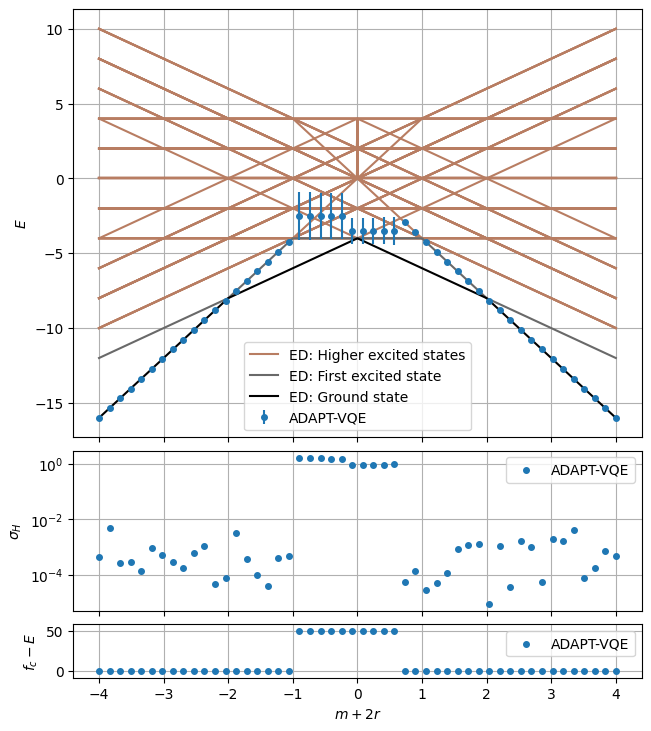

In [6]:
with h5py.File(f"{data_folder}{"2025-11-46"}.hdf5", "r") as f:
    avqe_2_loader = ResultLoader(f["2025-11-18_13-11-50-23954408"])
    print(avqe_2_loader.get_hamiltonian_type())
    avqe_2_energy, avqe_2_mass = avqe_2_loader.get_energy_mass({})
    avqe_2_f_c, _ = avqe_2_loader.get_hamiltonian_mass({})
    avqe_2_h_var, avqe_2_mass_v = avqe_2_loader.get_hamiltonian_variance_mass({})

fig, (ax, var_ax, pen_ax) = plt.subplots(3, sharex=True, figsize=(6.4, 4.8 * 1.5), layout="constrained",
                                         height_ratios=[2, 0.75, 0.25])

pen_ax.set_axisbelow(True)
pen_ax.grid(True)
var_ax.set_axisbelow(True)
var_ax.grid(True)
ax.set_axisbelow(True)
ax.grid(True)

pen_ax.set(xlabel='$m+2r$', ylabel=r'$f_c-E$')
var_ax.set(ylabel=r'$\sigma_H$')
var_ax.set_yscale("log")
ax.set(ylabel=r'$E$')

pen_ax.scatter(avqe_2_mass + 2, avqe_2_f_c - avqe_2_energy, label="ADAPT-VQE",
               marker='.', s=64, color=color_cycle[0])

var_ax.scatter(avqe_2_mass_v + 2, np.sqrt(avqe_2_h_var), label="ADAPT-VQE",
               marker='.', s=64, color=color_cycle[0])

ax.plot(ed_mass + 2, ed_energy[:, 2:68], color=hes_color)[0].set_label("ED: Higher excited states")
ax.plot(ed_mass + 2, ed_energy[:, 1], label="ED: First excited state", color=es_color)
ax.plot(ed_mass + 2, ed_energy[:, 0], label="ED: Ground state", color=gs_color)
ax.errorbar(avqe_2_mass + 2, avqe_2_energy, np.sqrt(avqe_2_h_var), label="ADAPT-VQE", zorder=2.5, ls="",
            marker=".", ms=8, color=color_cycle[0])

ax_x_lim = ax.get_xlim()
ax_y_lim = ax.get_ylim()
pen_ax_y_lim = pen_ax.get_ylim()
pen_ax_scaler = 0.1
pen_ax.set_ylim([pen_ax_y_lim[0] - pen_ax_scaler * (pen_ax_y_lim[1] - pen_ax_y_lim[0]),
                 pen_ax_y_lim[1] + pen_ax_scaler * (pen_ax_y_lim[1] - pen_ax_y_lim[0])])
pen_ax.legend()
var_ax.legend()
ax.legend()
fig.savefig(f"{output_filename}adapt_vqe_3_e_m.png", bbox_inches='tight', pad_inches=0, transparent=True)
fig.savefig(f"{output_filename}adapt_vqe_3_e_m.pdf", bbox_inches='tight', pad_inches=0, transparent=True)

In [7]:
with h5py.File(f"{data_folder}{"2025-09-35"}.hdf5", "r") as f:
    ed_loader = ResultLoader(f["2025-09-03_22-35-17"])
    ed_energy, ed_mass = ed_loader.get_energy_mass({})
    ed_c, _ = ed_loader.get_charge_conjugation_mass({})
    ed_c_v, _ = ed_loader.get_charge_conjugation_variance_mass({})

In [8]:
with h5py.File(f"{data_folder}{"2025-11-46"}.hdf5", "r") as f:
    avqe_2_loader = ResultLoader(f["2025-11-18_13-11-50-23954408"])
    print(avqe_2_loader.get_hamiltonian_type())
    avqe_2_energy, avqe_2_mass = avqe_2_loader.get_energy_mass({})
    avqe_2_f_c, _ = avqe_2_loader.get_hamiltonian_mass({})
    avqe_2_h_var, avqe_2_mass_v = avqe_2_loader.get_hamiltonian_variance_mass({})
    avqe_2_c, avqe_2_mass_c = avqe_2_loader.get_charge_conjugation_mass({})

ZeroChargePenalty


In [9]:
with h5py.File(f"{data_folder}{"2026-01-01"}.hdf5", "r") as f:
    avqe_3_loader = ResultLoader(f["2026-01-07_14-31-34-24236398"])
    print(avqe_3_loader.get_hamiltonian_type())
    avqe_3_energy, avqe_3_mass = avqe_3_loader.get_energy_mass({})
    avqe_3_f_c, _ = avqe_3_loader.get_hamiltonian_mass({})
    avqe_3_h_var, avqe_3_mass_v = avqe_3_loader.get_hamiltonian_variance_mass({})
    avqe_3_c, avqe_3_mass_c = avqe_3_loader.get_charge_conjugation_mass({})

ZeroChargePenalty


In [10]:
with h5py.File(f"{data_folder}{"2026-01-02"}.hdf5", "r") as f:
    avqe_4_loader = ResultLoader(f["2026-01-11_00-57-15-24245100"])
    print(avqe_4_loader.get_hamiltonian_type())
    avqe_4_energy, avqe_4_mass = avqe_4_loader.get_energy_mass({})
    avqe_4_f_c, _ = avqe_4_loader.get_hamiltonian_mass({})
    avqe_4_h_var, avqe_4_mass_v = avqe_4_loader.get_hamiltonian_variance_mass({})
    avqe_4_c, avqe_4_mass_c = avqe_4_loader.get_charge_conjugation_mass({})

ZeroChargePenalty


In [11]:
with h5py.File(f"{data_folder}{"2026-01-02"}.hdf5", "r") as f:
    avqe_5_loader = ResultLoader(f["2026-01-11_01-16-50-24245112"])
    print(avqe_5_loader.get_hamiltonian_type())
    avqe_5_energy, avqe_5_mass = avqe_5_loader.get_energy_mass({})
    avqe_5_f_c, _ = avqe_5_loader.get_hamiltonian_mass({})
    avqe_5_h_var, avqe_5_mass_v = avqe_5_loader.get_hamiltonian_variance_mass({})
    avqe_5_c, avqe_5_mass_c = avqe_5_loader.get_charge_conjugation_mass({})

ZeroChargePenalty


In [12]:
avqe_energies = [avqe_2_energy, avqe_3_energy, avqe_4_energy, avqe_5_energy]
avqe_masses = [avqe_2_mass, avqe_3_mass, avqe_4_mass, avqe_5_mass]
avqe_masse_cs = [avqe_2_mass_c, avqe_3_mass_c, avqe_4_mass_c, avqe_5_mass_c]
avqe_cs = [avqe_2_c, avqe_3_c, avqe_4_c, avqe_5_c]

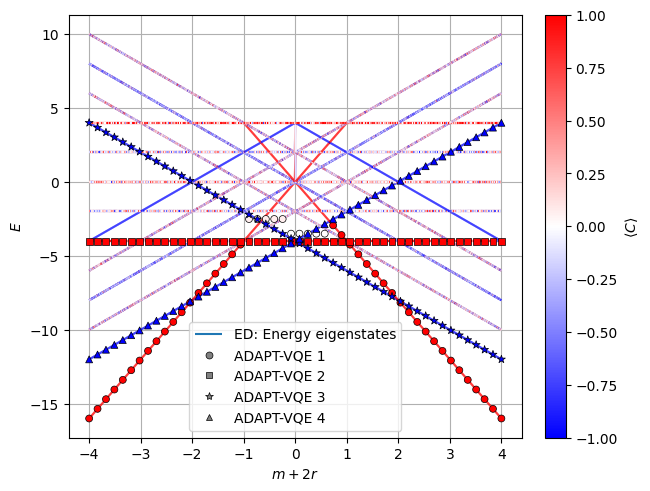

In [13]:
fig, ax = plt.subplots(layout="constrained")
ax.set_axisbelow(True)
ax.grid(True)
ax.set(xlabel='$m+2r$', ylabel=r'$E$')

cmap = plt.get_cmap('bwr')
norm = plt.Normalize(vmin=-1, vmax=1)
legends = []

for i in range(68):
    points = np.array([ed_mass + 2, ed_energy[:, i]]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=norm)
    lc.set_array(ed_c[:, i])
    lc.set_zorder(2)
    if i == 0:
        lc.set_label("ED: Energy eigenstates")
        legends.append(lc)
    line = ax.add_collection(lc)

labels = ["ADAPT-VQE 1", "ADAPT-VQE 2", "ADAPT-VQE 3", "ADAPT-VQE 4"]
markers = ['o', 's', '*', '^']
for avqe_energy, avqe_mass, avqe_mass_c, avqe_c, my_marker in zip(avqe_energies, avqe_masses, avqe_masse_cs, avqe_cs, markers):
    ax.scatter(avqe_mass + 2, avqe_energy, c=avqe_c, norm=norm, cmap=cmap, marker=my_marker,
               s=36 if my_marker == "*" else 25, zorder=2.5, edgecolor="black", linewidths=0.5)

ax.set_xlim(ax_x_lim)
ax.set_ylim(ax_y_lim)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cbar.set_label(r'$\left\langle C \right\rangle$')


for my_marker, label in zip(markers, labels):
    legends.append(Line2D([], [], marker=my_marker, linestyle='', markersize=6 if my_marker == "*" else 5,
                              color='gray', markeredgecolor="black", label=label, markeredgewidth=0.5))

ax.legend(handles=legends, loc="lower center")
fig.show()

fig.savefig(f"{output_filename}e_c_m_combined.png", bbox_inches='tight', pad_inches=0, transparent=True)
fig.savefig(f"{output_filename}e_c_m_combined.pdf", bbox_inches='tight', pad_inches=0, transparent=True)